# Práctica 4b: lectura de matrículas (OCR)

Este cuaderno aborda el pipeline de detección con la lectura del texto de cada matrícula, comparando dos alternativas de OCR:

- **EasyOCR**: OCR clásico basado en redes de detección y reconocimiento de texto.
- **SmolVLM2-500M**: modelo de visión-lenguaje (VLM) al que se le pide que lea la matrícula.

Contenido:
1. Carga de modelos y funciones de inferencia.
2. Creación del *ground truth* (texto real de las matrículas, etiquetado a mano).
3. Comparativa de ambos OCR en tiempo de inferencia y acierto.
4. Generación del vídeo y del CSV con la matrícula leída.

**Importación de modulos necesarios para la ejecución del notebook**

In [11]:
import time
from pathlib import Path

import cv2
import easyocr
import pandas as pd
import torch
from PIL import Image
from transformers import AutoModelForImageTextToText, AutoProcessor
from ultralytics import RTDETR

import re
import matplotlib.pyplot as plt
from IPython.display import clear_output


**Carga de modelos**

Se cargarán los modelos de detección de matrículas y de OCR y VLM.

In [ ]:
val_images_dir = Path("./OCR_Dataset/val/images")
plate_model = RTDETR("./runs/detect/rtdetr_runs/plates_detection/weights/best.pt")

# OCR: EasyOCR
easy_reader = easyocr.Reader(['es', 'en'], gpu=torch.cuda.is_available())
device = "cuda" if torch.cuda.is_available() else "cpu"

# VLM: SmolVLM2
model_id = "HuggingFaceTB/SmolVLM2-500M-Instruct"
proccessor = AutoProcessor.from_pretrained(model_id)
vlm_model = (
        AutoModelForImageTextToText.from_pretrained(
        model_id,
        dtype=torch.bfloat16 if torch.cuda.is_available() else torch.float32,
        _attn_implementation="sdpa",
    )
    .to(device)
    .eval()
)

print("device:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "CPU")

**Funciones de inferencia**

Se definirán las funciones de inferencia para el reconocimiento de texto. 

Para que la comparación sea justa, ambos modelos reciben el mismo tratamiento de entrada y normalización.

In [ ]:
SCALE = 2
ALLOW = "ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789"


def prep(img):
    """Mismo preprocesado para los dos modelos."""
    h, w = img.shape[:2]
    return cv2.resize(img, (w * SCALE, h * SCALE), interpolation=cv2.INTER_CUBIC)


def norm(s):
    return re.sub(r"[^A-Z0-9]", "", str(s).upper())


def lev(a, b):
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]


def infer_easyocr(img):
    img = prep(img)
    start = time.perf_counter()
    result = easy_reader.readtext(img, detail=0, allowlist=ALLOW)
    text = norm("".join(result))
    return text, (time.perf_counter() - start) * 1000


def infer_smolvlm2(img):
    image = Image.fromarray(cv2.cvtColor(prep(img), cv2.COLOR_BGR2RGB))
    messages = [{
        "role": "user",
        "content": [
            {"type": "image"},
            {"type": "text",
             "text": "Read the license plate. Reply ONLY with its letters and digits, without any extra words."},
        ],
    }]
    start = time.perf_counter()
    prompt = proccessor.apply_chat_template(messages, add_generation_prompt=True)
    inputs = proccessor(text=prompt, images=[image], return_tensors="pt").to(device)
    
    generated_ids = vlm_model.generate(**inputs, max_new_tokens=15)
    generated_texts = proccessor.batch_decode(generated_ids, skip_special_tokens=True)
    
    text = norm(generated_texts[0].split("Assistant:")[-1])
    return text, (time.perf_counter() - start) * 1000

**Recortes reales y etiquetado**

Para medir el acierto se precisda de conocer el texto real de cada matrícula. El dataset solo trae las cajas, por lo que se deberá etiquetar el texto a mano:

1. `gt_crop` recorta la matrícula usando la **anotación real** del dataset, no la del detector. Así se evalúan solo los OCR, sin influencia de los fallos de detección, y los dos modelos ven exactamente los mismos recortes.
2. Para cada imagen se muestra el recorte y se escribe la matrícula. Enter vacío = ilegible (se descarta) y `q` = salir.
3. Cada respuesta se guarda al instante en `ground_truth.csv` (`imagen,texto`). Al volver a ejecutar la celda se saltan las imágenes ya etiquetadas.


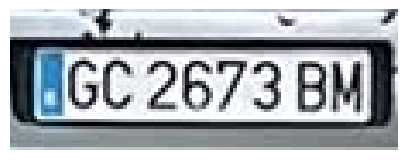

Matrículas etiquetadas: 81


In [ ]:
labels_dir = val_images_dir.parent / "labels"

IMG_EXTS = {".jpg", ".jpeg", ".png"}
image_files = sorted(p for p in val_images_dir.iterdir() if p.suffix.lower() in IMG_EXTS)


def gt_crop(img_path):
    """Recorte de la matrícula según la anotación real del dataset."""
    frame = cv2.imread(str(img_path))
    lf = labels_dir / (img_path.stem + ".txt")
    if frame is None or not lf.exists():
        return None
    lines = lf.read_text().strip().splitlines()
    if not lines:
        return None
    _, cx, cy, bw, bh = map(float, lines[0].split()[:5])
    H, W = frame.shape[:2]
    x1, y1 = max(0, int((cx - bw / 2) * W)), max(0, int((cy - bh / 2) * H))
    x2, y2 = int((cx + bw / 2) * W), int((cy + bh / 2) * H)
    crop = frame[y1:y2, x1:x2]
    return crop if crop.size else None


gt_path = Path("ground_truth.csv")
gt = pd.read_csv(gt_path, dtype=str) if gt_path.exists() else pd.DataFrame(columns=["imagen", "texto"])
done = set(gt["imagen"])

for p in image_files:
    if p.name in done:
        continue
    crop = gt_crop(p)
    if crop is None:
        continue
    clear_output(wait=True)
    plt.figure(figsize=(5, 2)); plt.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.show()
    txt = input(f"{p.name} (vacío = ilegible, 'q' = salir): ").strip()
    if txt.lower() == "q":
        break
    if txt:
        gt.loc[len(gt)] = [p.name, norm(txt)]
        gt.to_csv(gt_path, index=False)

print("Matrículas etiquetadas:", len(gt))

**Ejecución**

Se cargarán las etiquetas para generar los recortes de las imágenes etiquetadas. A continuación, se realizará un calentamiento de cada modelo para que ambos se ejecuten a tiempos similares. 

Finalmente, cada recorte se pasa a cada uno de los modelos con las mismas condiciones.

In [13]:
gt = pd.read_csv("ground_truth.csv", dtype=str).set_index("imagen")["texto"]
crops = {}
for p in image_files:
    if p.name in gt.index:
        c = gt_crop(p)
        if c is not None:
            crops[p.name] = c

# Calentamiento (no se mide)
first = next(iter(crops.values()))
for _ in range(3):
    infer_easyocr(first)
    infer_smolvlm2(first)

results = []
for name, crop in crops.items():
    text_easy, time_easy = infer_easyocr(crop)
    text_smol, time_smol = infer_smolvlm2(crop)
    results.append({
        "Imagen": name,
        "Texto_Real": gt[name],
        "Texto_EasyOCR": text_easy,
        "Tiempo_EasyOCR_ms": time_easy,
        "Texto_SmolVLM2": text_smol,
        "Tiempo_SmolVLM2_ms": time_smol,
    })

print("Imágenes evaluadas:", len(results))

Imágenes evaluadas: 81


**Cálculo de las métricas**

- **Exact match (%)**: porcentaje de matrículas leídas exactamente igual que la real.
- **CER (%)**: errores por carácter (inserciones, borrados y sustituciones) respecto al total de caracteres reales. Es menos estricta que el exact match, porque un solo carácter mal no invalida toda la lectura. Menor es mejor.
- **Tiempo medio, mediana y desviación (ms)** de la inferencia por imagen. La mediana es más representativa si hay valores atípicos.

Los resultados por imagen se guardan en `comparativa_ocr.csv`.

**Condiciones del experimento:** 81 imágenes del conjunto de validación, mismos recortes, mismo preprocesado y normalización para ambos modelos, calentamiento previo, GPU NVIDIA GeForce RTX 5070 Laptop (8 GB), Python 3.9.21, PyTorch 2.8.0 + CUDA 12.8.

In [14]:
df_results = pd.DataFrame(results)

rows = []
for m in ["EasyOCR", "SmolVLM2"]:
    pred, real = df_results[f"Texto_{m}"], df_results["Texto_Real"]
    t = df_results[f"Tiempo_{m}_ms"]
    rows.append({
        "Modelo": m,
        "Exact match (%)": (pred == real).mean() * 100,
        "CER (%)": sum(lev(p, r) for p, r in zip(pred, real)) / real.str.len().sum() * 100,
        "Tiempo medio (ms)": t.mean(),
        "Tiempo mediana (ms)": t.median(),
        "Tiempo std (ms)": t.std(),
    })
comparativa = pd.DataFrame(rows).set_index("Modelo")

df_results.to_csv("comparativa_ocr.csv", index=False)
display(comparativa.round(2))

,Exact match (%),CER (%),Tiempo medio (ms),Tiempo mediana (ms),Tiempo std (ms)
Modelo,,,,,
EasyOCR,29.63,38.20,50.70,29.72,49.38
SmolVLM2,32.10,39.96,582.28,536.07,213.81


**Vídeo con OCR**

Se recorre el vídeo fotograma a fotograma y, usando las coordenadas del CSV de detecciones (`mx1, my1, mx2, my2`).

In [ ]:
# Configuración de archivos de entrada y salida
video_input = "output_rtdetr.mp4"
csv_input = "detections_rtdetr.csv"

video_output = "output_rtdetr_ocr.avi"
csv_output = "detections_rtdetr_ocr.csv"

df = pd.read_csv(csv_input)

if "texto_matricula" not in df.columns:
    df["texto_matricula"] = ""

vid = cv2.VideoCapture(video_input)
fps = vid.get(cv2.CAP_PROP_FPS)
w = int(vid.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(vid.get(cv2.CAP_PROP_FRAME_HEIGHT))
out = cv2.VideoWriter(video_output, cv2.VideoWriter_fourcc(*"XVID"), fps, (w, h))

frame_n = 0

while True:
    ret, frame = vid.read()
    if not ret:
        break
    frame_n += 1

    # Filtrar las detecciones que corresponden a este fotograma exacto
    detecciones_frame = df[df["fotograma"] == frame_n]

    for index, row in detecciones_frame.iterrows():
        if row["matricula_en_su_caso"] == "Si":
            mx1 = max(0, int(row["mx1"]))
            my1 = max(0, int(row["my1"]))
            mx2 = min(w, int(row["mx2"]))
            my2 = min(h, int(row["my2"]))

            # Recortar la región de la matrícula
            crop_matricula = frame[my1:my2, mx1:mx2]

            if crop_matricula.size > 0:
                texto_final, _ = infer_easyocr(crop_matricula)

                # Guardar el texto en el DataFrame
                df.at[index, "texto_matricula"] = texto_final

                # Visualización en el fotograma
                cv2.putText(
                    frame,
                    texto_final,
                    (mx1, my1 - 10),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.8,
                    (0, 255, 0),
                    2,
                )

    out.write(frame)

vid.release()
out.release()

df.to_csv(csv_output, index=False, encoding="utf-8")

print("Proceso completado")
print(f"Vídeo con textos OCR guardado en: {video_output}")
print(f"CSV actualizado guardado en: {csv_output}")

Vídeo con textos OCR guardado en: output_rtdetr_ocr.avi
CSV actualizado guardado en: detections_rtdetr_ocr.csv
